<a href="https://colab.research.google.com/github/bramhani007/192425319-MLA0204/blob/main/Practical_Problem_13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving car_prices.csv to car_prices.csv
DATASET:
    Year  Km_Driven  Engine_CC  Price_Lakhs
0   2018      35000       1200          5.5
1   2019      28000       1200          6.2
2   2017      50000       1500          5.8
3   2020      20000       1200          7.0
4   2016      65000       1500          4.8
5   2021      15000       1200          8.0
6   2015      80000       1000          3.5
7   2018      45000       1800          7.2
8   2019      30000       1600          7.8
9   2022      10000       1500         10.5
10  2014      90000       1200          3.0
11  2020      25000       1800          9.2
12  2017      55000       1200          4.9
13  2021      18000       2000         11.5
14  2016      70000       1000          3.8
15  2022      12000       1800         11.0
16  2018      40000       1500          6.5
17  2020      22000       1500          8.1
18  2015      75000       1800          5.4
19  2019      32000       2000          9.0

Actual Car Prices:
[ 5.5  

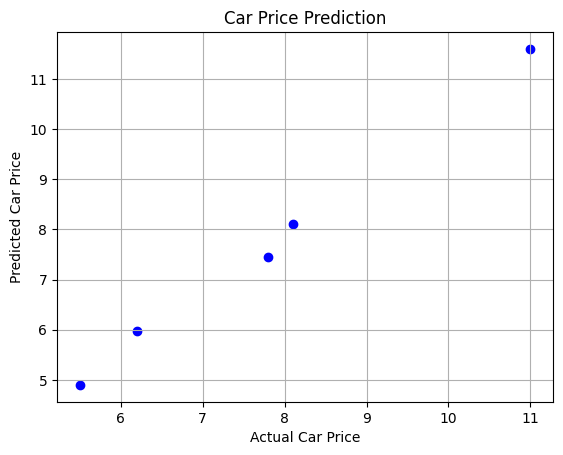

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import io
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

# Upload dataset
uploaded = files.upload()
filename = next(iter(uploaded))
data = pd.read_csv(io.BytesIO(uploaded[filename]))

print("DATASET:")
print(data)

# Input features
X = data[["Year", "Km_Driven", "Engine_CC"]]

# Target variable
y = data["Price_Lakhs"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42
)

# Create Linear Regression model
model = LinearRegression()

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

print("\nActual Car Prices:")
print(y_test.values)

print("\nPredicted Car Prices:")
print(y_pred)

# Evaluation
print("\nMean Absolute Error:")
print(mean_absolute_error(y_test, y_pred))

print("\nMean Squared Error:")
print(mean_squared_error(y_test, y_pred))

print("\nR2 Score:")
print(r2_score(y_test, y_pred))

# Predict new car price
new_car = pd.DataFrame({
    "Year": [2021],
    "Km_Driven": [20000],
    "Engine_CC": [1500]
})

predicted_price = model.predict(new_car)

print("\nPredicted Car Price:")
print(predicted_price[0], "Lakhs")

# Actual vs predicted graph
plt.scatter(y_test, y_pred, color="blue")

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")

plt.title("Car Price Prediction")

plt.grid()
plt.show()